# Exercise Sheet 2: Visualization
### Download the data file 'galahamr.sav' located in the Moodle exercises page, which contains measurements of physical properties of ~7000 nearby stars.

In [6]:
import numpy as np
from matplotlib import pyplot as plt

In [9]:
#Read in data set
from scipy.io import readsav
filepath = 'Numerische_Methoden/galahamr.sav'
stars = readsav(filepath)  

In [10]:
#Pull out some attributes of the stars we want to look at and store them in arrays
logg = stars['f']['logg']  #surface gravity   
teff = stars['f']['teff']  #effective temperature
mass = stars['f']['massmean']  #mass
lum = mass**4.  #luminosity for stars 0.43 < Msun < 2
age = stars['f']['agemean'] #age
feh = stars['f']['__fe_h_'] #[Fe/H], a logarithmic Iron abundance
afe = stars['f']['__alpha_fe_']  #[Alpha/Fe], logarithmic relative abundance of alpha elements(O, Si, etc.) relative to Iron

# Question 1: Plot the stars from Galah in two different ways!
### a) a scatter plot with the points colored by age

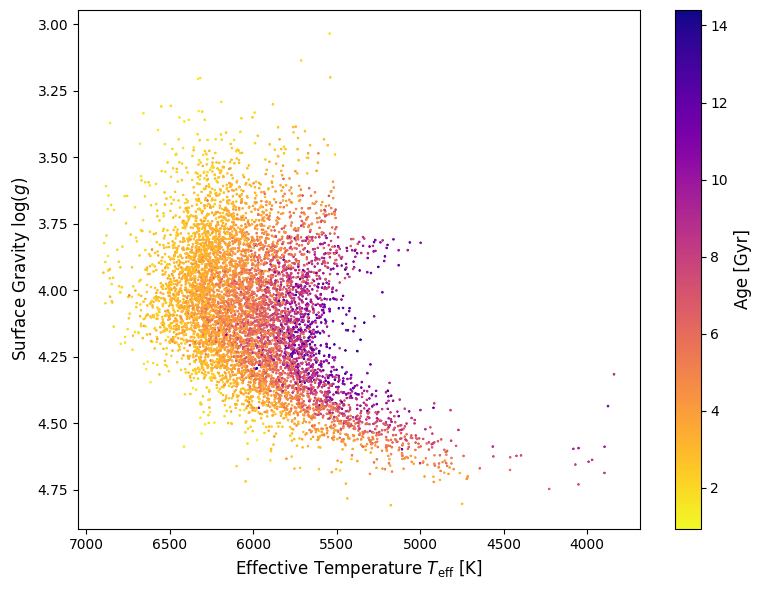

In [23]:
plt.figure(figsize=(8, 6))

sc = plt.scatter(teff, logg,
                 c=age,
                 cmap='plasma_r',
                 s=1,
                 marker='*')

plt.xlabel(r'Effective Temperature $T_{\rm eff}$ [K]', fontsize=12)
plt.ylabel(r'Surface Gravity $\log(g)$', fontsize=12)

cbar = plt.colorbar(sc)
cbar.set_label('Age [Gyr]', fontsize=12)

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

#### - The hotter stars on the left are mostly young yellow/orange roughly 1–5 Gyr old 
#### - Many of the oldest stars are concentrated around roughly 5300–5800 K 
#### - age is not randomly distributed across the diagram, hotter stars tend to be younger, while older stars are concentrated at somewhat cooler temperatures

### b) a 2D density plot using, e.g. the kde package along with the pcolormesh routine in matplotlib; or hist2d within matplotlib

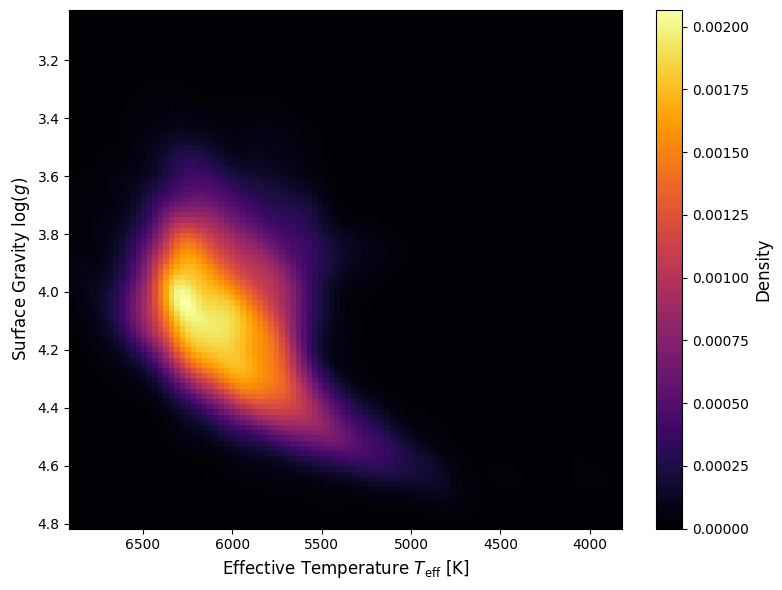

In [12]:
from scipy.stats import gaussian_kde

x = np.linspace(teff.min(), teff.max(), 100)
y = np.linspace(logg.min(), logg.max(), 100)
X, Y = np.meshgrid(x, y)

kde = gaussian_kde([teff, logg])
Z = kde([X.ravel(), Y.ravel()]).reshape(X.shape)

plt.figure(figsize=(8, 6))

plt.pcolormesh(X, Y, Z,
               shading='auto',
               cmap='inferno')

plt.xlabel(r'Effective Temperature $T_{\rm eff}$ [K]', fontsize=12)
plt.ylabel(r'Surface Gravity $\log(g)$', fontsize=12)

cbar = plt.colorbar()
cbar.set_label('Density', fontsize=12)

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

#### - The highest density is approximately around 6000-6300 K (mainly late F-type to early G-type stars).
#### - There is also an elongated distribution toward cooler temperatures and larger log(g), rather than the stars being uniformly distributed

# Question 2: Calculate a running average of Effective Temperature as a function of log(g) and draw that average as a line over the stars

In [13]:
bins = np.linspace(logg.min(), logg.max(), 30)
bin_centers = (bins[:-1] + bins[1:]) / 2
mean_teff = []
valid_centers = []

for i in range(len(bins) - 1):
    mask = (logg >= bins[i]) & (logg < bins[i+1])
    if np.any(mask):
        mean_teff.append(np.mean(teff[mask]))
        valid_centers.append(bin_centers[i])

mean_teff = np.array(mean_teff)
valid_centers = np.array(valid_centers)

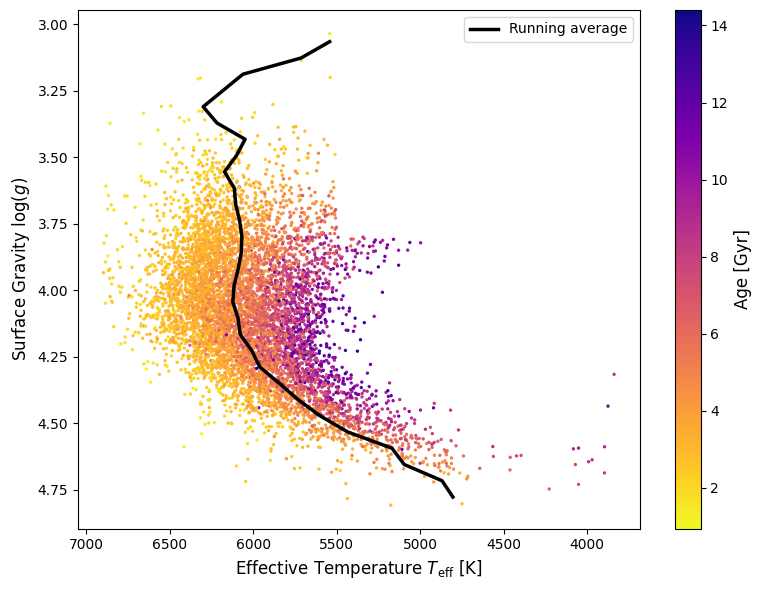

In [14]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(teff, logg,
                 c=age,
                 cmap='plasma_r',
                 s=2)

plt.plot(mean_teff, valid_centers,
         color='black',
         linewidth=2.5,
         linestyle='-',
         label='Running average')

plt.xlabel(r'Effective Temperature $T_{\rm eff}$ [K]', fontsize=12)
plt.ylabel(r'Surface Gravity $\log(g)$', fontsize=12)

cbar = plt.colorbar(sc)
cbar.set_label('Age [Gyr]', fontsize=12)

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.legend()

plt.tight_layout()
plt.show()

### Question 3: Compute the mean and standard deviation ($\sigma$) of the ages of the cool and hot star sub-samples

In [15]:
teff_boundary = np.interp(logg, valid_centers, mean_teff)
hot = teff > teff_boundary
cool = teff <= teff_boundary

In [16]:
age_hot = age[hot]
age_cool = age[cool]

mean_hot = np.mean(age_hot)
std_hot = np.std(age_hot)

mean_cool = np.mean(age_cool)
std_cool = np.std(age_cool)

print('Hot stars:')
print('Mean age =', mean_hot)
print('Standard deviation =', std_hot)

print('Cool stars:')
print('Mean age =', mean_cool)
print('Standard deviation =', std_cool)

Hot stars:
Mean age = 3.6530194828053073
Standard deviation = 1.154659767928059
Cool stars:
Mean age = 6.796408680699675
Standard deviation = 2.3135787583500065


In [17]:
lower = mean_hot + std_hot
upper = mean_cool - std_cool

within = (age >= lower) & (age <= upper)

percentage = np.sum(within) / len(age) * 100

print(f'Hot stars:  mean = {mean_hot:.2f} Gyr, σ = {std_hot:.2f} Gyr')
print(f'Cool stars: mean = {mean_cool:.2f} Gyr, σ = {std_cool:.2f} Gyr')

print(f'Lower age limit = {lower:.2f} Gyr')
print(f'Upper age limit = {upper:.2f} Gyr')
print(f'Percentage = {percentage:.1f}%')

Hot stars:  mean = 3.65 Gyr, σ = 1.15 Gyr
Cool stars: mean = 6.80 Gyr, σ = 2.31 Gyr
Lower age limit = 4.81 Gyr
Upper age limit = 4.48 Gyr
Percentage = 0.0%


### Cool stars are older on average than hot stars. The 1σ age ranges overlap, so there is no interval between the upper 1σ limit of the hot stars and the lower 1σ limit of the cool stars. Therefore, the percentage is 0%.

# Question 4: Create two versions of a weighted 2D density distribution of the sample of stars in the plane of [Fe/H] as a function of age:
### a) One where the density distribution is weighted by the mass of the stars

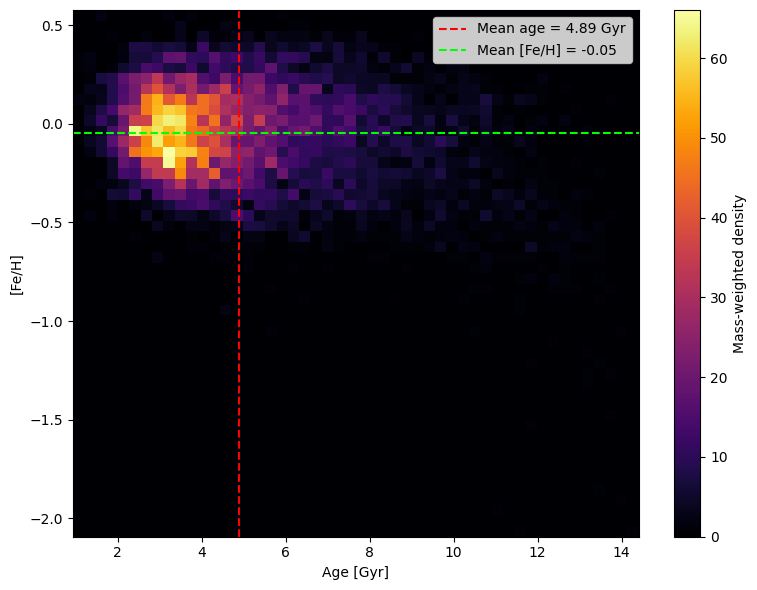

Mass-weighted mean age = 4.89 Gyr
Mass-weighted mean [Fe/H] = -0.05


In [18]:
mean_age_mass = np.average(age, weights=mass)
mean_feh_mass = np.average(feh, weights=mass)

plt.figure(figsize=(8, 6))

plt.hist2d(age, feh,
           bins=50,
           weights=mass, #a star with more mass contributes more weight to its bin
           cmap='inferno')

plt.xlabel('Age [Gyr]')
plt.ylabel('[Fe/H]')

cbar = plt.colorbar()
cbar.set_label('Mass-weighted density')

plt.axvline(mean_age_mass, color='red', linestyle='--',
            label=f'Mean age = {mean_age_mass:.2f} Gyr')

plt.axhline(mean_feh_mass, color='lime', linestyle='--',
            label=f'Mean [Fe/H] = {mean_feh_mass:.2f}')

plt.legend()
plt.tight_layout()
plt.show()

print(f'Mass-weighted mean age = {mean_age_mass:.2f} Gyr')
print(f'Mass-weighted mean [Fe/H] = {mean_feh_mass:.2f}')

### b) One where the density distribution is weighted by the luminosity of the stars

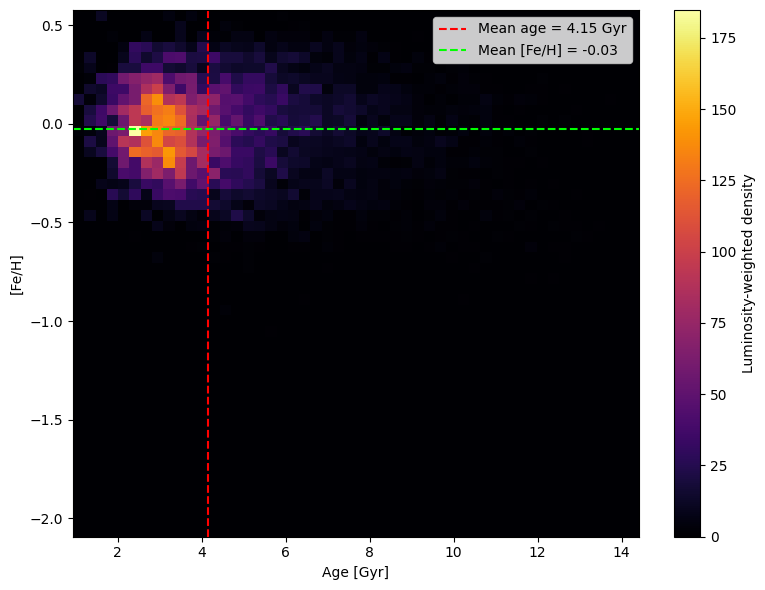

Luminosity-weighted mean age = 4.15 Gyr
Luminosity-weighted mean [Fe/H] = -0.03


In [19]:
mean_age_lum = np.average(age, weights=lum)
mean_feh_lum = np.average(feh, weights=lum)

plt.figure(figsize=(8, 6))

plt.hist2d(age, feh,
           bins=50,
           weights=lum,
           cmap='inferno')

plt.xlabel('Age [Gyr]')
plt.ylabel('[Fe/H]')

cbar = plt.colorbar()
cbar.set_label('Luminosity-weighted density')

plt.axvline(mean_age_lum, color='red', linestyle='--',
            label=f'Mean age = {mean_age_lum:.2f} Gyr')

plt.axhline(mean_feh_lum, color='lime', linestyle='--',
            label=f'Mean [Fe/H] = {mean_feh_lum:.2f}')

plt.legend()
plt.tight_layout()
plt.show()

print(f'Luminosity-weighted mean age = {mean_age_lum:.2f} Gyr')
print(f'Luminosity-weighted mean [Fe/H] = {mean_feh_lum:.2f}')

### So luminosity weighting shifts the mean toward younger stars.
### The luminosity-weighted sample has a lower mean age (4.15 Gyr) than the mass-weighted sample (4.89 Gyr), showing that the more luminous stars in this sample tend to be younger. The mean metallicity changes only slightly from [Fe/H] = −0.05 to −0.03, so the choice of weighting has a much stronger effect on the mean age than on the mean metallicity.